In [2]:
import numpy as np
import multiprocessing
from joblib import Parallel, delayed
from msmbuilder.decomposition import tICA
from msmbuilder.msm import MarkovStateModel
from msmbuilder.cluster import KMeans, MiniBatchKMeans, KCenters

In [3]:
#Loads tICA trajectories from a saved NumPy file.
tica_trajs = np.load("./tica_trajs_2000_100.npy", allow_pickle=True)

In [5]:
#Returns the number of trajectories loaded from file.
len(tica_trajs)

1234

In [6]:
print(tica_trajs[0])        # first trajectory
print(tica_trajs[-1])       # last trajectory

[[-0.76178971 -0.1261756   0.34328876  0.14724553  0.09129766]
 [-0.89582596  0.0389738   0.1508542   0.04301637  0.12308158]
 [-0.83304362  0.05444477  0.02811521  0.0770852  -0.01387563]
 ...
 [-1.10552884  0.21748699  0.00239055 -0.24790154  0.01876017]
 [-1.17083716  0.2541579   0.02376553 -0.15025804 -0.05348367]
 [-1.12906098  0.27386232 -0.06355133 -0.17507382  0.00233042]]
[[0.32039272 0.52956903 1.12906628 0.36212838 0.6252741 ]
 [0.17395982 0.3813064  1.45259841 0.38772664 1.11926755]
 [0.22349632 0.4873747  1.31285799 0.56878308 0.78064083]
 ...
 [0.19751174 0.69187258 1.67952708 0.60819622 0.85458149]
 [0.25525506 0.76714909 1.84246834 0.73225129 0.94173038]
 [0.25371559 0.64496076 1.76796445 0.9227189  0.82957231]]


In [7]:
#Creates an array seed to hold the first tICA frame of each trajectory.
seed = np.zeros((len(tica_trajs), 5))
for i in range(len(tica_trajs)):
    seed[i] = tica_trajs[i][0]

#Loads labels from a text file label.txt

labels = np.loadtxt("./label_2000.txt", dtype=int)

In [8]:
print(labels)

[  0   0   0 ... 251 251 251]


In [10]:
#Creates a new list of trajectories keeping only the first 3 tICA dimensions per frame. 
#Reduces dimensionality of all tICA trajectories to 3.
new_tica = []
dim = 3

for i in range(len(tica_trajs)):  
    new_tica.append(tica_trajs[i][:,:dim])  

In [11]:
#Prints the number of trajectories (should match original count).
print(len(new_tica))

#Prints the total number of frames when all trajectories are concatenated together.
print(len(np.concatenate(new_tica)))

1234
1507720


In [27]:
#Creates a KMeans clustering object
cluster = KMeans(n_clusters=120, random_state=0, n_init=1)

#Applies the clustering algorithm to new_tica trajectories - assign frames to clusters and also give distances
clustered_trajs = cluster.fit_transform(new_tica) #fit_transform: Fits the cluster centers and returns the distance of each point to each cluster center.

#convert clustered_trajs to a NumPy array of objects
# clustered_trajs = np.array(clustered_trajs, dtype=object)

In [28]:
#find how the MSM implied timescales change with lag time
lt = np.arange(1, 1001, 1)
timescales = np.zeros((len(lt), 8))
for i in range(len(lt)):
    msm = MarkovStateModel(n_timescales=10, lag_time=lt[i], ergodic_cutoff='off', 
                       reversible_type='transpose', verbose=False)
    msm.fit(clustered_trajs)
    timescales[i] = msm.timescales_[:8]

In [29]:
#Retrieves the equilibrium populations of each MSM state after the model is fit. # of outputs = # n_clusters
msm.populations_

array([0.02384332, 0.00633469, 0.0076941 , 0.02196736, 0.00324719,
       0.01078849, 0.00866806, 0.01107536, 0.01667465, 0.00843837,
       0.00726035, 0.00288147, 0.00545142, 0.00776015, 0.00449225,
       0.00377164, 0.00856061, 0.00256601, 0.00573139, 0.00305102,
       0.00740329, 0.00523652, 0.00838711, 0.00420834, 0.02915279,
       0.00537157, 0.00698531, 0.01996621, 0.00624991, 0.01103593,
       0.00481164, 0.00472588, 0.00164528, 0.00226436, 0.0105105 ,
       0.00210269, 0.00290118, 0.00744962, 0.00429805, 0.00089806,
       0.00715191, 0.0066669 , 0.00874988, 0.0057235 , 0.00542875,
       0.01468631, 0.00564858, 0.00413244, 0.01135828, 0.01009351,
       0.01242589, 0.0034759 , 0.00799871, 0.00532721, 0.00657227,
       0.00402005, 0.00909293, 0.02938051, 0.00879424, 0.00584278,
       0.01036165, 0.00582208, 0.00795237, 0.00418468, 0.00408216,
       0.00013702, 0.01713403, 0.0019006 , 0.00986875, 0.00594432,
       0.02037925, 0.01517625, 0.00371545, 0.02791661, 0.00646

In [30]:
#Returns the eigenvalues of the MSM’s transition matrix
msm.eigenvalues_

array([1.        , 0.98975185, 0.94246467, 0.93730351, 0.88763849,
       0.86218631, 0.85393106, 0.81536377, 0.79720801, 0.79437628,
       0.78437876])

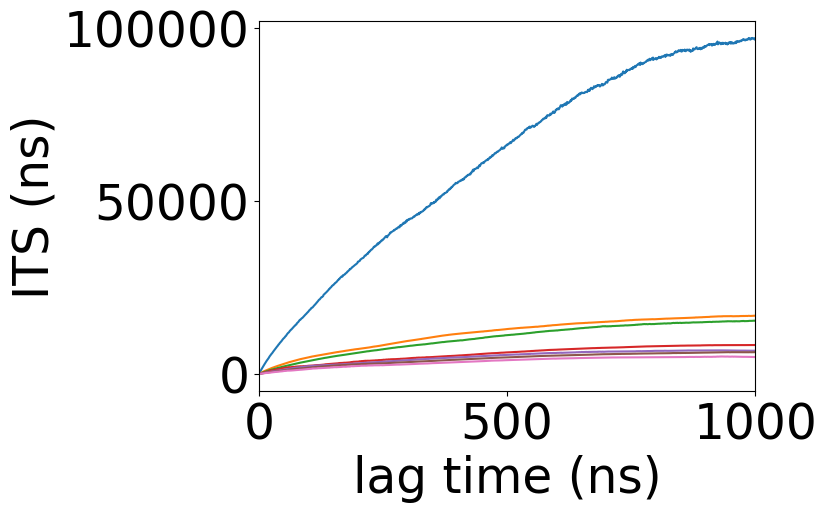

In [31]:
#assess convergence and determine a good lag time for MSM construction
from matplotlib import pyplot as plt

plt.plot(lt, timescales[:,0])
plt.plot(lt, timescales[:,1])
plt.plot(lt, timescales[:,2])
plt.plot(lt, timescales[:,3])
plt.plot(lt, timescales[:,4])
plt.plot(lt, timescales[:,5])
plt.plot(lt, timescales[:,6])

plt.xlabel('lag time (ns)')
plt.ylabel('ITS (ns)')
plt.xlim(0, 1000)
# plt.ylim(0, 20000)
plt.show()

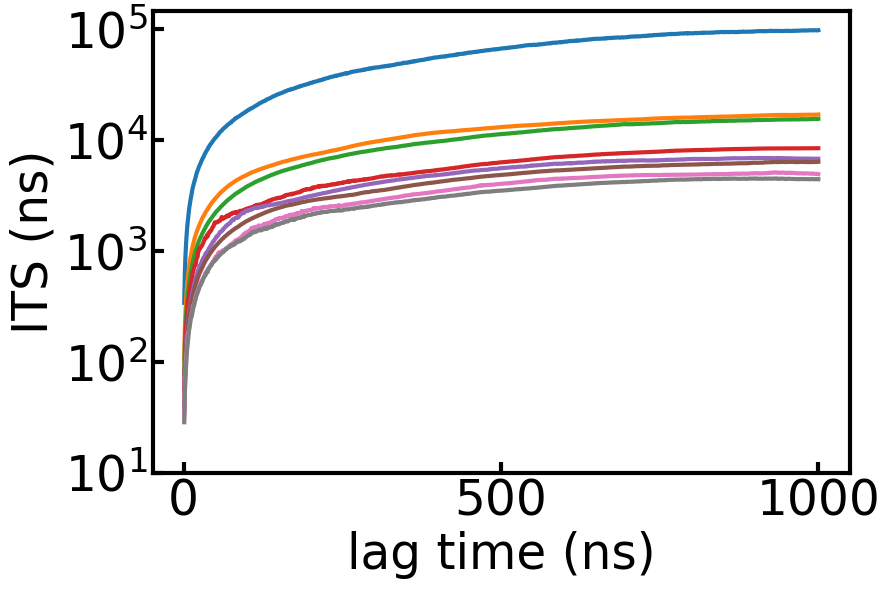

In [32]:
#Creates a log-scale plot of the first 8 implied timescales vs lag time
from matplotlib import pyplot as plt

plt.rcParams['font.size'] = 35
fig, ax = plt.subplots(figsize=(9, 6))

plt.plot(lt, np.log10(timescales[:,0]), linewidth=3)
plt.plot(lt, np.log10(timescales[:,1]), linewidth=3)
plt.plot(lt, np.log10(timescales[:,2]), linewidth=3)
plt.plot(lt, np.log10(timescales[:,3]), linewidth=3)
plt.plot(lt, np.log10(timescales[:,4]), linewidth=3)
plt.plot(lt, np.log10(timescales[:,5]), linewidth=3)
plt.plot(lt, np.log10(timescales[:,6]), linewidth=3)
plt.plot(lt, np.log10(timescales[:,7]), linewidth=3)

# plt.plot(lt, np.log10(timescales[:,8]), linewidth=2)
# plt.plot(lt, np.log10(timescales[:,9]), linewidth=2)
plt.yticks([1,2,3,4,5], ["$10^1$", "$10^2$","$10^3$","$10^4$","$10^5$"])
plt.xlabel('lag time (ns)')
plt.ylabel('ITS (ns)')
# plt.colorbar()
ax.tick_params(axis='both', direction='in', width=3, length=8)
for spine in ax.spines.values():
        spine.set_linewidth(3)
plt.show()

In [33]:
#np.save("microstate_its.npy", timescales)

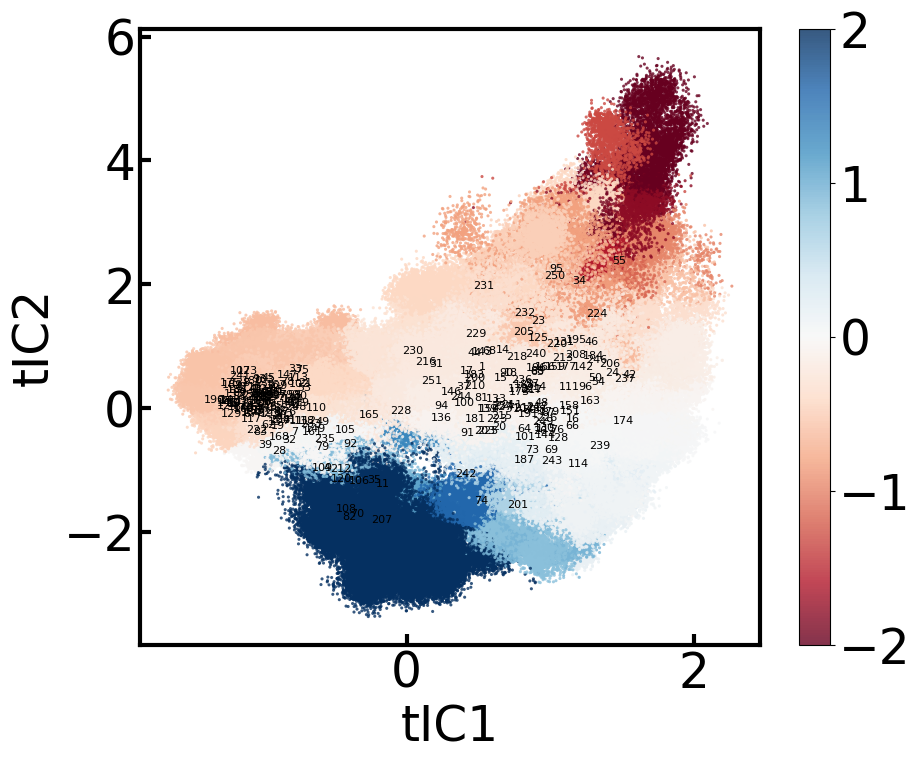

In [34]:
# @title 4 dihedral macrostates pojected on contacts tICs
macro_mapping = np.concatenate(clustered_trajs)

plt.rcParams['font.size'] = 35
fig, ax = plt.subplots(figsize=(10, 8))
colors = np.array(['#ef8a62', '#67a9cf', '#2166ac','#b2182b', 'g', 'purple', ])

plt.scatter(np.concatenate(new_tica)[:,0], np.concatenate(new_tica)[:,1], s=5,
            c=msm.right_eigenvectors_[:,2][np.concatenate(clustered_trajs)], alpha=0.8, linewidth=0, cmap='RdBu', vmin=-2, vmax=2)

unique_labels = np.unique(labels)
# For each unique label, randomly select one point
for label in unique_labels:
    # Get indices of all points with this label
    label_indices = np.where(labels == label)[0]
    # print(label_indices)
    # Randomly select one of these indices
    random_index = np.random.choice(label_indices)
    # Get the coordinates of the selected point
    x, y = seed[random_index,:2]
    # Annotate the point with its label
    plt.text(x, y, str(label), fontsize=8, ha='right', va='bottom')

plt.xlabel('tIC1')
plt.ylabel('tIC2')
plt.colorbar()
ax.tick_params(axis='both', direction='in', width=3, length=8)
for spine in ax.spines.values():
        spine.set_linewidth(3)

plt.show()

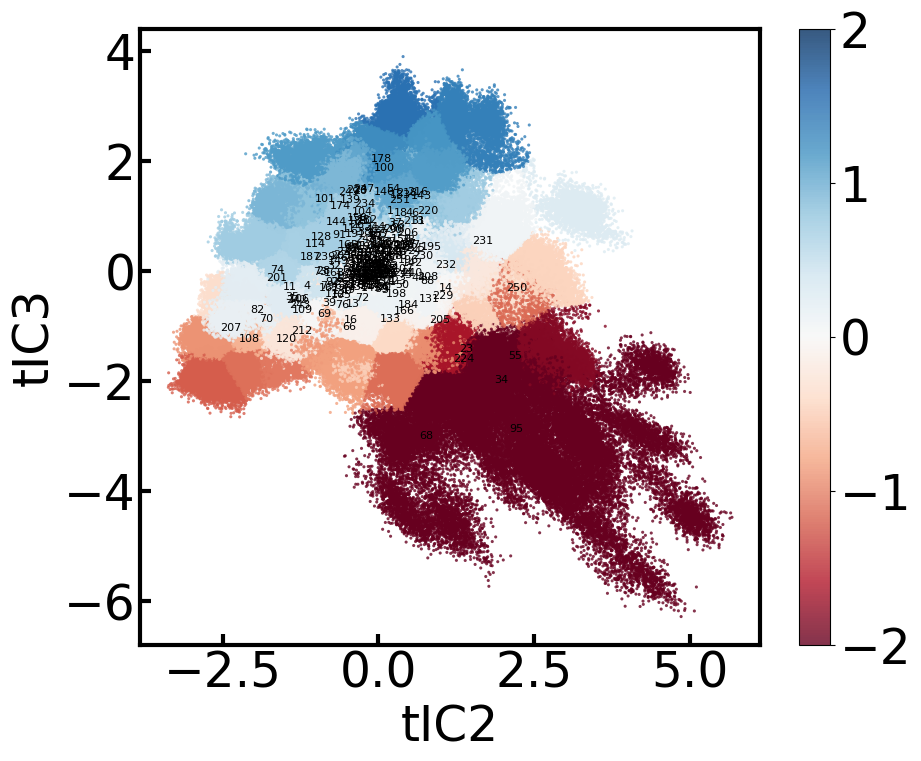

In [35]:
# @title 4 dihedral macrostates pojected on contacts tICs
macro_mapping = np.concatenate(clustered_trajs)

plt.rcParams['font.size'] = 35
fig, ax = plt.subplots(figsize=(10, 8))
colors = np.array(['#ef8a62', '#67a9cf', '#2166ac','#b2182b', 'g', 'purple', ])

plt.scatter(np.concatenate(new_tica)[:,1], np.concatenate(new_tica)[:,2], s=5,
            c=msm.right_eigenvectors_[:,3][np.concatenate(clustered_trajs)], alpha=0.8, linewidth=0, cmap='RdBu', vmin=-2, vmax=2)

unique_labels = np.unique(labels)
# For each unique label, randomly select one point
for label in unique_labels:
    # Get indices of all points with this label
    label_indices = np.where(labels == label)[0]
    # print(label_indices)
    # Randomly select one of these indices
    random_index = np.random.choice(label_indices)
    # Get the coordinates of the selected point
    x, y = seed[random_index,1:3]
    # Annotate the point with its label
    plt.text(x, y, str(label), fontsize=8, ha='right', va='bottom')

plt.xlabel('tIC2')
plt.ylabel('tIC3')
plt.colorbar()
ax.tick_params(axis='both', direction='in', width=3, length=8)
for spine in ax.spines.values():
        spine.set_linewidth(3)

plt.show()

### The following code takes a lot of time!

In [36]:
#Generates 252 individual plots, one for each trajectory or macrostate label. 
#Each plot shows: All frames colored by MSM eigenvector 1 (tIC2 vs tIC3 projection).

import matplotlib.pyplot as plt
import numpy as np

# Precompute concatenated arrays once
all_tica = np.concatenate(new_tica)
macro_mapping = np.concatenate(clustered_trajs)
color_values = msm.right_eigenvectors_[:, 1][macro_mapping]

plt.rcParams['font.size'] = 35
colors = np.array(['#ef8a62', '#67a9cf', '#2166ac', '#b2182b', 'g', 'purple'])

for idx in range(252):
    fig, ax = plt.subplots(figsize=(10, 8))
    
    # Faster scatter using ax instead of plt
    sc = ax.scatter(all_tica[:, 1], all_tica[:, 2], s=5, c=color_values, alpha=0.8, linewidth=0, cmap='RdBu', vmin=-2, vmax=2)

    label_indices = np.where(labels == idx)[0]

    for i in label_indices:
        ax.plot(tica_trajs[i][:, 1], tica_trajs[i][:, 2], color='k')

    ax.set_xlabel('tIC1')
    ax.set_ylabel('tIC2')
    plt.colorbar(sc, ax=ax)
    
    ax.tick_params(axis='both', direction='in', width=3, length=8)
    for spine in ax.spines.values():
        spine.set_linewidth(3)

    fig.savefig(f"seed{idx}.png")
    plt.close(fig)  # avoid memory buildup


In [37]:
#Builds an MSM from microstate trajectories.
from msmbuilder.lumping import PCCAPlus
n_macro = 4
msm = MarkovStateModel(n_timescales=7, lag_time=100, reversible_type='transpose',
                       verbose=False, ergodic_cutoff='off')
msm.fit(clustered_trajs)
pcca = PCCAPlus.from_msm(msm, n_macrostates=n_macro)
lumped_trajs = pcca.fit_transform(clustered_trajs)

msm = MarkovStateModel(n_timescales=5, lag_time=100, ergodic_cutoff='off', 
                       reversible_type='transpose', verbose=False)
msm.fit(lumped_trajs)
print(msm.populations_)

/Users/eshanig/miniforge3/envs/msm/lib/python3.9/site-packages/scipy/optimize/_numdiff.py:590: RuntimeWarning: invalid value encountered in subtract
  df = fun(x) - f0


Optimization terminated successfully.
         Current function value: -3.880020
         Iterations: 11
         Function evaluations: 101
Optimization terminated successfully.
         Current function value: -3.880020
         Iterations: 11
         Function evaluations: 101
[0.01750101 0.44861268 0.07383083 0.46005548]


[94 95 96 97 98]


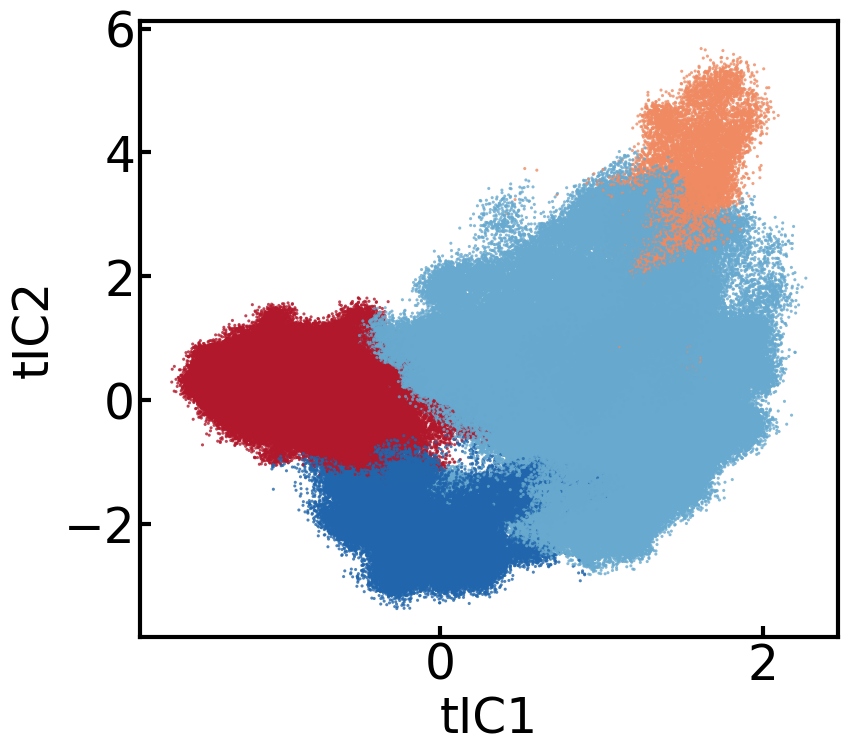

In [38]:
# @title 4 dihedral macrostates pojected on contacts tICs
#Shows all MD frames projected onto tIC1 vs. tIC2.
#Colors each frame by its PCCA-lumped macrostate (from MSM)

macro_mapping = np.concatenate(clustered_trajs)

plt.rcParams['font.size'] = 35
fig, ax = plt.subplots(figsize=(9, 8))
colors = np.array(['#ef8a62', '#67a9cf', '#2166ac','#b2182b', 'g', 'purple', 'y'])

plt.scatter(np.concatenate(new_tica)[:,0], np.concatenate(new_tica)[:,1], s=5,
            color=colors[np.concatenate(lumped_trajs)[::1]], alpha=0.8, linewidth=0)

label_indices = np.where(labels == 20)[0]
print(label_indices)
#for i in label_indices:
#     plt.plot(tica_trajs[i][:,0], tica_trajs[i][:,1], color = 'k')

trj_index = 188
# plt.plot(tica_trajs[trj_index][:,0], tica_trajs[trj_index][:,1], color = 'k')

#unique_labels = np.unique(labels)
 # For each unique label, randomly select one point
#for label in unique_labels:
     # Get indices of all points with this label
#     label_indices = np.where(labels == label)[0]
     # print(label_indices)
     # Randomly select one of these indices
#     random_index = label_indices[0]
     # Get the coordinates of the selected point
#     x, y = seed[random_index,:2]
     # Annotate the point with its label
#     plt.text(x, y, str(label), fontsize=8, ha='right', va='bottom')

plt.xlabel('tIC1')
plt.ylabel('tIC2')
# plt.colorbar()
ax.tick_params(axis='both', direction='in', width=3, length=8)
for spine in ax.spines.values():
        spine.set_linewidth(3)

plt.show()

[94 95 96 97 98]


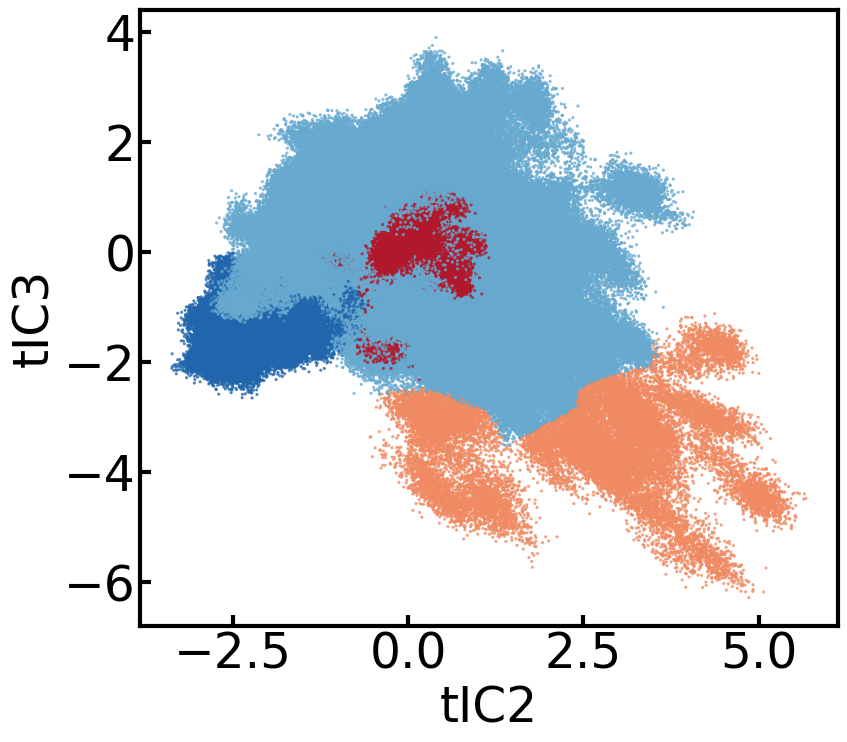

In [39]:
# @title 4 dihedral macrostates pojected on contacts tICs
#Visualizes the 4 macrostates projected onto tIC2 vs. tIC3 space.
#Color-coded by macrostate assignment

macro_mapping = np.concatenate(clustered_trajs)

plt.rcParams['font.size'] = 35
fig, ax = plt.subplots(figsize=(9, 8))
colors = np.array(['#ef8a62', '#67a9cf', '#2166ac','#b2182b', 'g', 'purple', 'y' ])

plt.scatter(np.concatenate(new_tica)[:,1], np.concatenate(new_tica)[:,2], s=5,
            color=colors[np.concatenate(lumped_trajs)[::1]], alpha=0.8, linewidth=0)

label_indices = np.where(labels == 20)[0]
print(label_indices)
# for i in label_indices:
#     plt.plot(tica_trajs[i][:,0], tica_trajs[i][:,1], color = 'k')

trj_index = 188
# plt.plot(tica_trajs[trj_index][:,0], tica_trajs[trj_index][:,1], color = 'k')

#unique_labels = np.unique(labels)
# For each unique label, randomly select one point
#for label in unique_labels:
    # Get indices of all points with this label
#    label_indices = np.where(labels == label)[0]
    # print(label_indices)
    # Randomly select one of these indices
#    random_index = np.random.choice(label_indices)
    # Get the coordinates of the selected point
#    x, y = seed[random_index,1:3]
    # Annotate the point with its label
#    plt.text(x, y, str(label), fontsize=8, ha='right', va='bottom')

plt.xlabel('tIC2')
plt.ylabel('tIC3')
# plt.colorbar()
ax.tick_params(axis='both', direction='in', width=3, length=8)
for spine in ax.spines.values():
        spine.set_linewidth(3)

plt.show()

In [40]:
#Prints long-time populations for these macrostates.

msm = MarkovStateModel(n_timescales=5, lag_time=100, ergodic_cutoff='off', 
                       reversible_type='transpose', verbose=False)
msm.fit(lumped_trajs)
print(msm.populations_)

[0.01750101 0.44861268 0.07383083 0.46005548]


In [41]:
resi = []

lt = np.arange(1, 401)
timescales = np.zeros((len(lt), 3))
for i in range(len(lt)):
    msm = MarkovStateModel(n_timescales=6, lag_time=lt[i], ergodic_cutoff='off', 
                       reversible_type='transpose', verbose=False)
    msm.fit(lumped_trajs)
    timescales[i] = msm.timescales_[:3]
    resi.append(np.diag(msm.transmat_))

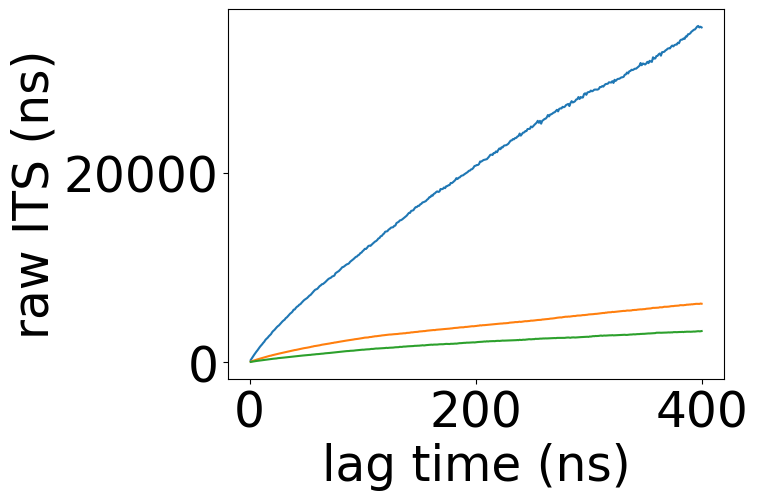

In [42]:
from matplotlib import pyplot as plt

plt.plot(lt, timescales[:,0])
plt.plot(lt, timescales[:,1])
plt.plot(lt, timescales[:,2])
# plt.plot(lt * 0.5, timescales[:,3]*0.5)
plt.xlabel('lag time (ns)')
plt.ylabel('raw ITS (ns)')
plt.show()

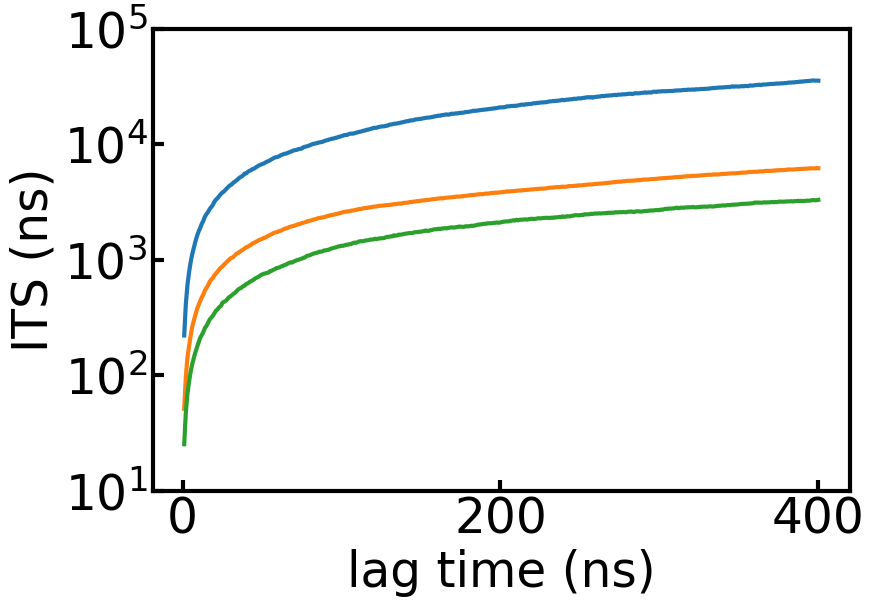

In [43]:
from matplotlib import pyplot as plt

plt.rcParams['font.size'] = 35
fig, ax = plt.subplots(figsize=(9, 6))
plt.plot(lt, np.log10(timescales[:,0]), linewidth=3)
plt.plot(lt, np.log10(timescales[:,1]), linewidth=3)
plt.plot(lt, np.log10(timescales[:,2]), linewidth=3)

plt.yticks([1,2,3,4,5], ["$10^1$", "$10^2$","$10^3$","$10^4$","$10^5$"])
plt.xlabel('lag time (ns)')
plt.ylabel('ITS (ns)')
# plt.ylim(0.9, 4.2)
# plt.colorbar()
ax.tick_params(axis='both', direction='in', width=3, length=8)
for spine in ax.spines.values():
        spine.set_linewidth(3)
plt.show()

In [50]:
from msmbuilder.msm import MarkovStateModel

n_states = 4
num_runs = 50
num_samples_per_run = 1234
lt = np.arange(1, 1501, 450)
def generate_TPM(trajs, lagtime, n_states=4,):
    TPM = []
    for i in range(len(lagtime)):
        msm_macro = MarkovStateModel(n_timescales=3, lag_time=lagtime[i],
                                     ergodic_cutoff='off', reversible_type='transpose', verbose=False)
        msm_macro.fit(trajs)
        if len(msm_macro.transmat_) != n_states:
            return None
        TPM.append(msm_macro.transmat_)
    return np.array(TPM)

bootstrap_TPM = np.zeros((num_runs, len(lt), n_states, n_states))
for i in range(num_runs):
    bootstrap_indices = np.random.choice(range(len(lumped_trajs)), size=num_samples_per_run, replace=True)
    bootstrap_trajs = [lumped_trajs[i] for i in bootstrap_indices]
    temp_TPM = generate_TPM(bootstrap_trajs, lagtime=lt)
    if temp_TPM is None:
        continue
    bootstrap_TPM[i] = temp_TPM
    print('Run {} is complete'.format(i))

Run 0 is complete
Run 1 is complete
Run 2 is complete
Run 3 is complete
Run 4 is complete
Run 5 is complete
Run 6 is complete
Run 7 is complete
Run 8 is complete
Run 9 is complete
Run 10 is complete
Run 11 is complete
Run 12 is complete
Run 13 is complete
Run 14 is complete
Run 15 is complete
Run 16 is complete
Run 17 is complete
Run 18 is complete
Run 19 is complete
Run 20 is complete
Run 21 is complete
Run 22 is complete
Run 23 is complete
Run 24 is complete
Run 25 is complete
Run 26 is complete
Run 27 is complete
Run 28 is complete
Run 29 is complete
Run 30 is complete
Run 31 is complete
Run 32 is complete
Run 33 is complete
Run 34 is complete
Run 35 is complete
Run 36 is complete
Run 37 is complete
Run 38 is complete
Run 39 is complete
Run 40 is complete
Run 41 is complete
Run 42 is complete
Run 43 is complete
Run 44 is complete
Run 45 is complete
Run 46 is complete
Run 47 is complete
Run 48 is complete
Run 49 is complete


In [51]:
lagtime = 450

msm = MarkovStateModel(n_timescales=6, lag_time=lagtime, ergodic_cutoff='off', 
                       reversible_type='transpose', verbose=False)
msm.fit(lumped_trajs)
transmat = msm.transmat_

order_parameter = np.arange(1, int(1500 / lagtime + 1))
msm_time = order_parameter * lagtime * 0.2
msm_TPM = []
for i in order_parameter:
    msm_TPM.append(np.linalg.matrix_power(transmat, i))
msm_TPM = np.array(msm_TPM)

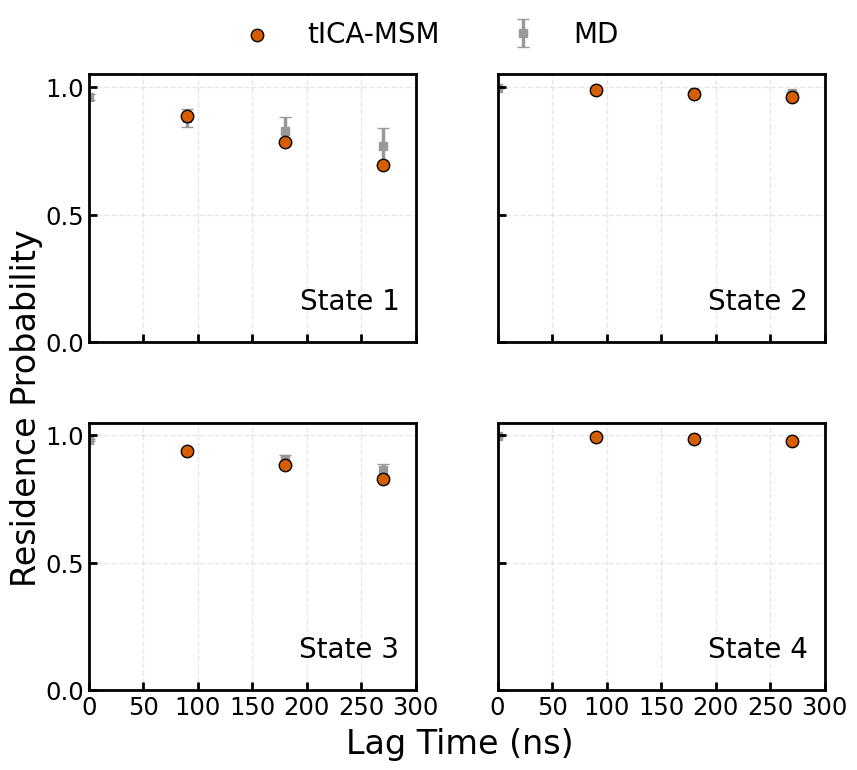

In [53]:
import matplotlib.pyplot as plt
import numpy as np


# Font and axis style
plt.rcParams['font.size'] = 17.5
plt.rcParams['axes.linewidth'] = 2

# Compute mean and std
TPM_mean = np.mean(bootstrap_TPM, axis=0)
TPM_std = np.std(bootstrap_TPM, axis=0)

color_msm = '#D55E00' 
color_md = '#999999'   # gray

# Create subplots
fig, axes = plt.subplots(2, 2, figsize=(9, 7.5), sharex=True, sharey=True)
axes = axes.flatten()

for i in range(n_states):
    ax = axes[i]

    # MD error bars
    ax.errorbar(x=lt * 0.2, y=TPM_mean[:, i, i], yerr=TPM_std[:, i, i], fmt='s', capsize=4, elinewidth=2.5, markersize=6, 
                color=color_md, ecolor=color_md, zorder=1, label='MD' if i == 0 else None)

    # MSM predictions as dark blue circles
    ax.scatter(msm_time, msm_TPM[:, i, i], c=color_msm, edgecolor='k', s=80, zorder=3, label='tICA-MSM' if i == 0 else None)


    # State label
    ax.text(0.95, 0.10, f'State {i+1}', ha='right', va='bottom', transform=ax.transAxes, fontsize=20)

    ax.set_ylim(0, 1.05)
    #ax.set_xlim(min(lt * 0.2), max(lt * 0.2))
    #ax.set_xticks([100, 200, 300])
    ax.set_xlim(0, 150)
    ax.set_xticks([0, 50, 100, 150,200, 250,300])
    ax.set_yticks([0.0, 0.5, 1.0])
    ax.tick_params(axis='both', direction='in', width=2, length=6)

    # Add clean gridlines
    ax.grid(True, linestyle='--', linewidth=1, alpha=0.3)

    # Border thickness
    for spine in ax.spines.values():
        spine.set_linewidth(2)

# Axis labels
fig.text(0.54, 0.04, 'Lag Time (ns)', ha='center', fontsize=24)
fig.text(0.04, 0.5, 'Residence Probability', va='center', rotation='vertical', fontsize=24)

# Unified legend
handles, labels = [], []
for ax in axes:
    for h, l in zip(*ax.get_legend_handles_labels()):
        if l not in labels:
            handles.append(h)
            labels.append(l)

fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, 1.05),
           ncol=2, fontsize=20, frameon=False)

plt.tight_layout(rect=[0.05, 0.05, 1, 0.98])
plt.subplots_adjust(wspace=0.25, hspace=0.3)
plt.show()

## Microstate CK test

In [54]:
from msmbuilder.msm import MarkovStateModel

n_states = 120
num_runs = 50
num_samples_per_run = 1234
lt = np.arange(1, 5501, 450)
def generate_TPM(trajs, lagtime, n_states=120,):
    TPM = []
    for i in range(len(lagtime)):
        msm = MarkovStateModel(n_timescales=3, lag_time=lagtime[i],
                                     ergodic_cutoff='off', reversible_type='transpose', verbose=False)
        msm.fit(trajs)
        if len(msm.transmat_) != n_states:
            return None
        TPM.append(msm.transmat_)
    return np.array(TPM)

bootstrap_TPM = np.zeros((num_runs, len(lt), n_states, n_states))

for i in range(num_runs):
    bootstrap_indices = np.random.choice(range(len(clustered_trajs)), size=num_samples_per_run, replace=True)
    bootstrap_trajs = [clustered_trajs[i] for i in bootstrap_indices]
    temp_TPM = generate_TPM(bootstrap_trajs, lagtime=lt)
    if temp_TPM is None:
        continue
    bootstrap_TPM[i] = temp_TPM
    print('Run {} is complete'.format(i))

/Users/eshanig/miniforge3/envs/msm/lib/python3.9/site-packages/msmbuilder/msm/msm.py:195: RuntimeWarning: invalid value encountered in divide
  transmat = rev_counts.astype(float) / rev_counts.sum(axis=1)[:, None]
/Users/eshanig/miniforge3/envs/msm/lib/python3.9/site-packages/msmbuilder/msm/msm.py:194: RuntimeWarning: invalid value encountered in divide
  populations /= populations.sum(dtype=float)


Run 0 is complete
Run 1 is complete
Run 2 is complete
Run 3 is complete
Run 4 is complete
Run 5 is complete
Run 7 is complete
Run 8 is complete
Run 9 is complete
Run 10 is complete
Run 11 is complete
Run 12 is complete
Run 13 is complete
Run 14 is complete
Run 15 is complete
Run 16 is complete
Run 17 is complete
Run 19 is complete
Run 20 is complete
Run 21 is complete
Run 22 is complete
Run 23 is complete
Run 24 is complete
Run 25 is complete
Run 26 is complete
Run 27 is complete
Run 28 is complete
Run 29 is complete
Run 30 is complete
Run 31 is complete
Run 32 is complete
Run 33 is complete
Run 34 is complete
Run 35 is complete
Run 36 is complete
Run 37 is complete
Run 39 is complete
Run 40 is complete
Run 42 is complete
Run 43 is complete
Run 44 is complete
Run 45 is complete
Run 47 is complete
Run 48 is complete
Run 49 is complete


In [55]:
lagtime = 450

msm = MarkovStateModel(n_timescales=6, lag_time=lagtime, ergodic_cutoff='off', 
                       reversible_type='transpose', verbose=False)
msm.fit(clustered_trajs)
transmat = msm.transmat_

order_parameter = np.arange(1, int(5500 / lagtime + 1))
msm_time = order_parameter * lagtime * 0.2
msm_TPM = []
for i in order_parameter:
    msm_TPM.append(np.linalg.matrix_power(transmat, i))
msm_TPM = np.array(msm_TPM)

In [56]:
TPM_mean = np.mean(bootstrap_TPM, axis=0)
TPM_std = np.std(bootstrap_TPM, axis=0)

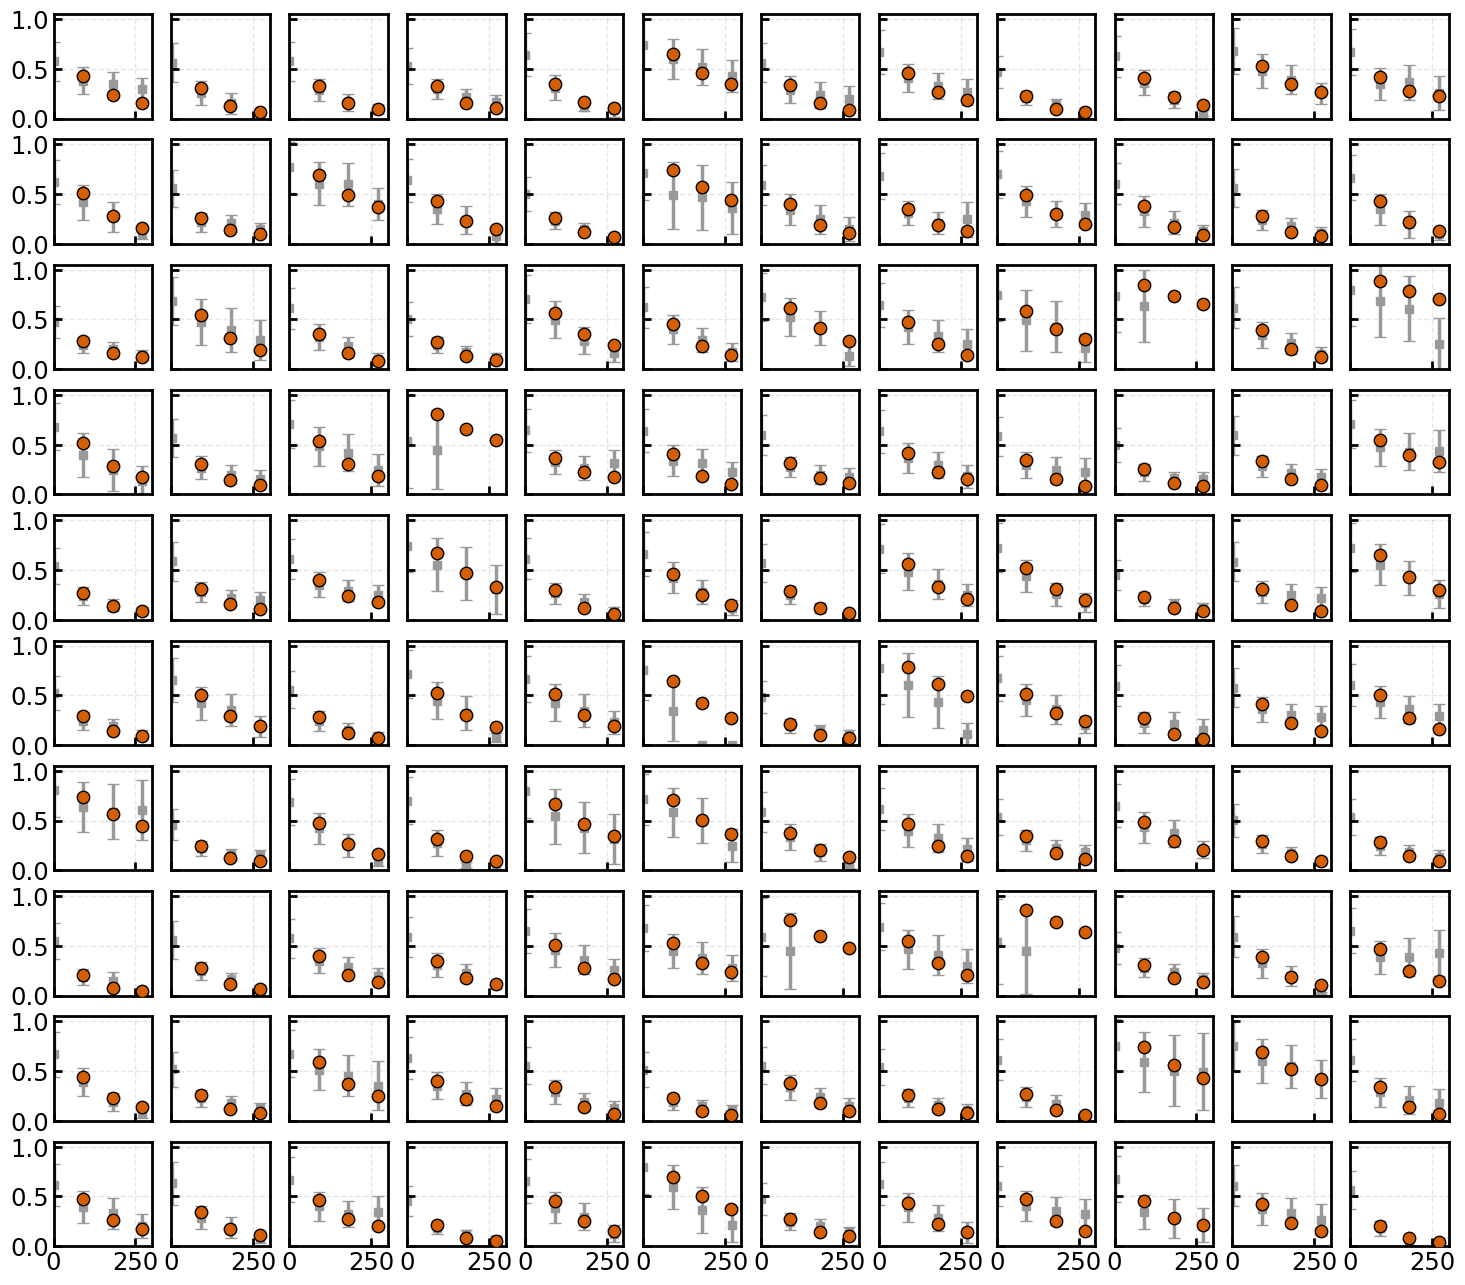

In [58]:
n_plot = 120   # number of microstates to show

cols = 12
rows = 10

fig, axes = plt.subplots(rows, cols, figsize=(18, 16), sharex=True, sharey=True)
axes = axes.flatten()

for i in range(n_plot):
    ax = axes[i]

    # MD error bars
    ax.errorbar(
        x=lt*0.2,
        y=TPM_mean[:, i, i],
        yerr=TPM_std[:, i, i],
        fmt='s',
        capsize=4,
        elinewidth=2.5,
        markersize=6,
        color=color_md,
        ecolor=color_md,
        zorder=1,
        label='MD' if i == 0 else None
    )

    # MSM prediction
    ax.scatter(
        msm_time,
        msm_TPM[:, i, i],
        c=color_msm,
        edgecolor='k',
        s=80,
        zorder=3,
        label='tICA-MSM' if i == 0 else None
    )

#    ax.text(0.95, 0.10, f'State {i+1}', ha='right', va='bottom',
#            transform=ax.transAxes, fontsize=20)

    ax.set_ylim(0, 1.05)
    ax.set_xlim(0, 300)
#    ax.set_xticks([0, 50, 100, 150])
    ax.set_yticks([0.0, 0.5, 1.0])
    ax.tick_params(axis='both', direction='in', width=2, length=6)
    ax.grid(True, linestyle='--', linewidth=1, alpha=0.3)

    for spine in ax.spines.values():
        spine.set_linewidth(2)

# Hide unused panels (if any)
for j in range(n_plot, len(axes)):
    axes[j].axis('off')


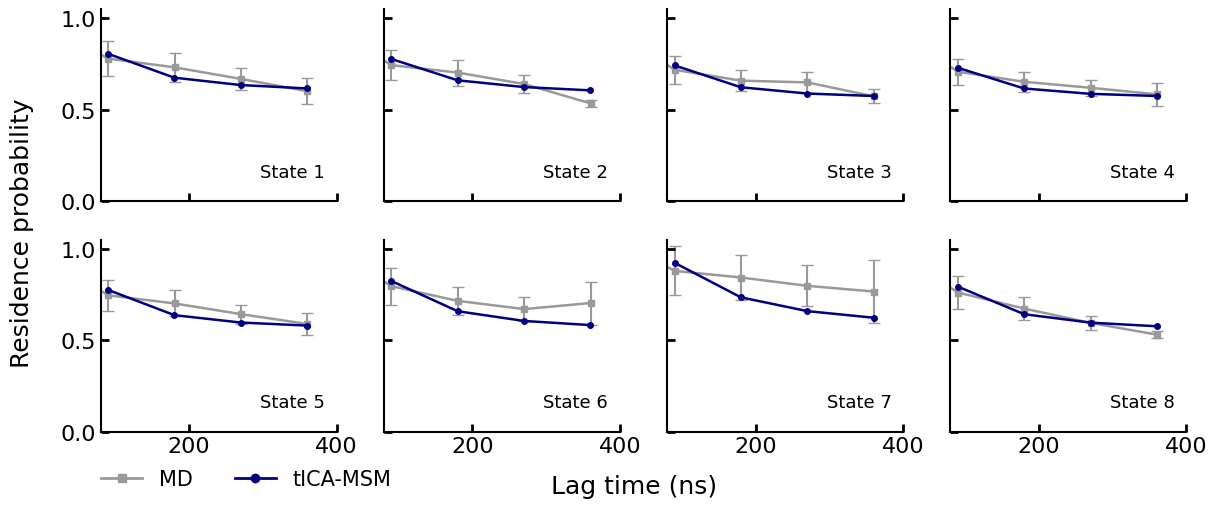

In [59]:
#8 most populated microstates

from matplotlib.lines import Line2D
state_counts = np.array([
    sum(np.sum(t == i) for t in clustered_trajs)
    for i in range(TPM_mean.shape[1])
])
top8_idx = np.argsort(state_counts)[::-1][:8]

n_plot = 8
cols = 4
rows = 2
fig, axes = plt.subplots(rows, cols, figsize=(12, 5), sharex=True, sharey=True)
axes = axes.flatten()

for plot_i, state_i in enumerate(top8_idx):
    ax = axes[plot_i]
    y_md  = TPM_mean[:, state_i, state_i] + 0.5
    ye_md = TPM_std[:, state_i, state_i]
    y_msm = msm_TPM[:, state_i, state_i] + 0.5

    ax.errorbar(
        x=lt * 0.2, y=y_md, yerr=ye_md,
        fmt='s-', capsize=4, elinewidth=1.5, markersize=4,
        linewidth=1.8, color=color_md, ecolor=color_md,
        zorder=1
    )
    mask = msm_time <= 360
    ax.plot(
        msm_time[mask], y_msm[mask],
        color='navy', linewidth=1.8,
        marker='o', markersize=4,
        zorder=3
    )

    ax.set_title('')  # remove title
    ax.text(0.95, 0.2, f'State {plot_i + 1}', transform=ax.transAxes,
        fontsize=13, ha='right', va='top')
    ax.set_ylim(0, 1.05)
    ax.set_xlim(80, 400)
    ax.set_yticks([0.0, 0.5, 1.0])
    ax.tick_params(axis='both', direction='in', width=2, length=6, labelsize=16)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    for spine in ['left', 'bottom']:
        ax.spines[spine].set_linewidth(1.5)

for j in range(n_plot, len(axes)):
    axes[j].axis('off')

fig.text(0.5, -0.02, 'Lag time (ns)', ha='center', fontsize=18)
fig.text(-0.02, 0.5, 'Residence probability', va='center', rotation='vertical', fontsize=18)

legend_handles = [
    Line2D([0], [0], color=color_md, linewidth=2, marker='s', markersize=6, label='MD'),
    Line2D([0], [0], color='navy', linewidth=2, marker='o', markersize=6, label='tICA-MSM'),
]
fig.legend(handles=legend_handles, fontsize=15, frameon=False,
           loc='lower left', bbox_to_anchor=(0.04, -0.05), ncol=2)

plt.tight_layout()
plt.subplots_adjust(hspace=0.2, wspace=0.2)

plt.show()

In [60]:
print(lt)
print(msm_time)

[   1  451  901 1351 1801 2251 2701 3151 3601 4051 4501 4951 5401]
[  90.  180.  270.  360.  450.  540.  630.  720.  810.  900.  990. 1080.]
